In [35]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import time
import copy

In [37]:
insta = 5
np.random.seed(126)

depcentral = pd.read_excel(r"DATOS.xlsx", sheet_name='deposito central')
pacientes  = pd.read_excel(r"DATOS.xlsx", sheet_name='Pacientes', index_col=2)
eco        = pd.read_excel(r"DATOS.xlsx", sheet_name='eco capital')

durserv = pd.read_excel(r"DATOS.xlsx", sheet_name='Tiempo de servicio', index_col=0)
durserv.columns = ['t']

tiempos = pd.read_excel(r'TIEMPOS.xlsx', sheet_name='tiempos', index_col=0)


distancias_km = pd.read_excel(r'DISTANCIA.xlsx', sheet_name='distancia', index_col=0) 

limtiemp =  6*60
limkits  = 36         

In [38]:
#################FUNCIONES IMPLEMENTADAS EN EL CODIGO################################

def rta_asig(rutas_optmizadas_2, rta_rutas_optmizadas_2):
    filas = []
    for i in range(len(rutas_optmizadas_2)):
        rut   = rutas_optmizadas_2[i][1]
        costo = rutas_optmizadas_2[i][0]

        for j in range(rut.shape[0]):
            cliente = rut.iat[j, 0]
            ruta    = rut.iat[j, 1]

            print(cliente)
            print(ruta)

            filas.append({
                'cliente': cliente,
                'costo':   costo,
                'ruta':    ruta
            })

    nuevo_df = pd.DataFrame(filas, columns=['cliente', 'costo', 'ruta'])

    return pd.concat([rta_rutas_optmizadas_2, nuevo_df], ignore_index=True)


#########################################################################################################

def rta_asig_costos(rutas_optmizadas, rta_rutas_optmizadas_costos):

    filas = []
    for i in range(len(rutas_optmizadas)):
        rut   = rutas_optmizadas[i][1]
        costo = rutas_optmizadas[i][0]

        cliente = rut.iat[0, 0]
        ruta    = rut.iat[0, 1]

        print(cliente, costo, ruta)

        filas.append({
            'cliente': cliente,
            'costo':   costo,
            'ruta':    ruta
        })

    nuevo_df = pd.DataFrame(filas, columns=['cliente', 'costo', 'ruta'])
    return pd.concat([rta_rutas_optmizadas_costos, nuevo_df], ignore_index=True)

#########################################################################################################

def swap(Cost, temp, eps=1e-6):

    newRoute = copy.deepcopy(temp)
    n = newRoute.shape[0]
    D = distancias[num_HOSPITAL][0]

    delta = 0.0
    bestI = -1
    bestJ = -1

    for i in range(1, n - 2):
        nodoI = newRoute.iat[i, 0]
        predI = newRoute.iat[i - 1, 0]
        sucI  = newRoute.iat[i + 1, 0]

        for j in range(i + 1, n - 2):
            nodoJ = newRoute.iat[j, 0]
            predJ = newRoute.iat[j - 1, 0]
            sucJ  = newRoute.iat[j + 1, 0]

            if j == i + 1:
                d = (D.loc[predI, nodoJ] + D.loc[nodoJ, nodoI] + D.loc[nodoI, sucJ]
                     - D.loc[predI, nodoI] - D.loc[nodoI, nodoJ] - D.loc[nodoJ, sucJ])
            else:
                d = (D.loc[predI, nodoJ] + D.loc[nodoJ, sucI]
                     + D.loc[predJ, nodoI] + D.loc[nodoI, sucJ]
                     - D.loc[predI, nodoI] - D.loc[nodoI, sucI]
                     - D.loc[predJ, nodoJ] - D.loc[nodoJ, sucJ])

            if d < delta - eps:
                delta = d
                bestI = i
                bestJ = j

    if bestI == -1:
        return [Cost, newRoute, False]

    newRoute.iat[bestI, 0], newRoute.iat[bestJ, 0] = \
        newRoute.iat[bestJ, 0], newRoute.iat[bestI, 0]

    return [Cost + delta, newRoute, True]

#########################################################################################################
def suma_costo(R_optmizadas):
    costo_total = 0
    for i in range(len(R_optmizadas)):
        costo_total += R_optmizadas[i][0]
    return costo_total
#########################################################################################################

def conteo_split(I, J, newRoute):
    dif = J - I
    costo_split = 0
    for i in range(dif):
        d = distancias[num_HOSPITAL][0].loc[newRoute.iat[I + i, 0], newRoute.iat[I + i + 1, 0]]
        costo_split += d
    return costo_split

#########################################################################################################

def conteo_quieto(I, J, newRoute):
    dif = J - I
    costo_split = 0
    for i in range(dif):
        d = distancias[num_HOSPITAL][0].loc[newRoute.iat[I + i, 0], newRoute.iat[I + i + 1, 0]]
        costo_split += d
    return costo_split

#########################################################################################################
def twoOptimal_1(Cost, ruta):

    newRoute = copy.deepcopy(ruta)
    n = newRoute.shape[0]
    D = distancias[num_HOSPITAL][0]

    delta = 0.0
    bestI = -1
    bestJ = -1

    for i in range(1, n - 3):
        predTail = ruta.iat[i,     0]
        tail     = ruta.iat[i + 1, 0]

        for j in range(i + 2, n - 2):
            head    = ruta.iat[j,     0]
            sucHead = ruta.iat[j + 1, 0]

            delta_cand = (D.loc[predTail, head]
                          + D.loc[tail,     sucHead]
                          - D.loc[predTail, tail]
                          - D.loc[head,     sucHead])

            if delta_cand < delta:
                delta = delta_cand
                bestI = i + 1
                bestJ = j

    if bestI == -1:
        return [Cost, newRoute, False]

    newCost = Cost + delta

    lo = bestI
    hi = bestJ
    while lo < hi:
        newRoute.iat[lo, 0], newRoute.iat[hi, 0] = \
            newRoute.iat[hi, 0], newRoute.iat[lo, 0]
        lo += 1
        hi -= 1

    if newCost >= Cost:
        return [Cost, copy.deepcopy(ruta), False]

    return [newCost, newRoute, True]
#########################################################################################################

In [39]:
def _append_coords(Ruta, COOD_X, COOD_Y):
    for j in range(Ruta.shape[0]):
        client = Ruta.iat[j, 0]

        if client in pacientes.index:
            COOD_X.append(pacientes.loc[client, 'Latitud'])
            COOD_Y.append(pacientes.loc[client, 'Longitud'])

        elif client in ['H1', 'H2', 'H3']:

            col_lat = next((c for c in ['Latitud', 'Latitude', 'lat', 'LAT']
                            if c in depcentral.columns), None)
            col_lon = next((c for c in ['Longitud', 'Longitude', 'lon', 'LON']
                            if c in depcentral.columns), None)

            if col_lat is None or col_lon is None:
                print(f"[AVISO] No se encontraron columnas de Latitud/Longitud "
                      f"en 'deposito central'. Columnas: {depcentral.columns.tolist()}")
                return

            fila = None

            col_id = next((c for c in depcentral.columns
                           if depcentral[c].astype(str).isin(['H1', 'H2', 'H3']).any()),
                          None)
            if col_id is not None:
                match = depcentral[depcentral[col_id].astype(str) == client]
                if not match.empty:
                    fila = match.iloc[0]

            if fila is None and client in depcentral.index:
                fila = depcentral.loc[client]

            if fila is None:
                try:
                    pos = ['H1', 'H2', 'H3'].index(client)
                    if pos < len(depcentral):
                        fila = depcentral.iloc[pos]
                except ValueError:
                    pass

            if fila is not None:
                COOD_X.append(fila[col_lat])
                COOD_Y.append(fila[col_lon])
            else:
                print(f"[AVISO] No se encontraron coordenadas para {client} "
                      f"en 'deposito central'.")

        elif client == 'Eco':
            col_lat = next((c for c in ['Latitud', 'Latitude', 'lat', 'LAT']
                            if c in eco.columns), None)
            col_lon = next((c for c in ['Longitud', 'Longitude', 'lon', 'LON']
                            if c in eco.columns), None)
            if col_lat is not None and col_lon is not None:
                COOD_X.append(eco[col_lat].iloc[0])
                COOD_Y.append(eco[col_lon].iloc[0])
            else:
                print(f"[AVISO] No se encontraron columnas de Latitud/Longitud "
                      f"en 'eco capital'. Columnas: {eco.columns.tolist()}")

def uno_Mcolor_grafica(rutas_optmizadas, hospital):
    for i in range(len(rutas_optmizadas)):
        Ruta = copy.deepcopy(rutas_optmizadas[i][1])
        if Ruta.iat[0, 0] == hospital:
            COOD_X, COOD_Y = [], []
            _append_coords(Ruta, COOD_X, COOD_Y)
            if COOD_X:
                plt.plot(COOD_X, COOD_Y)


#############################################################################################################
def uno_UNIcolor_grafica(R_optmizadas, hospital):
    COOD_X, COOD_Y = [], []

    for i in range(len(R_optmizadas)):
        Ruta = copy.deepcopy(R_optmizadas[i][1])
        if Ruta.iat[0, 0] == hospital:
            _append_coords(Ruta, COOD_X, COOD_Y)

    if COOD_X:
        plt.plot(COOD_X, COOD_Y)


#############################################################################################################
def uno_UNIcolor_grafica_combinadas(R_optmizadas_1, R_optmizadas_2, hospital):

    for i in range(len(R_optmizadas_1)):
        Ruta = copy.deepcopy(R_optmizadas_1[i][1])
        if Ruta.iat[0, 0] == hospital:
            COOD_X, COOD_Y = [], []
            _append_coords(Ruta, COOD_X, COOD_Y)
            if COOD_X:
                plt.plot(COOD_X, COOD_Y, color='blue', marker='s', alpha=0.6, 
                         label='Método 1 (Original)' if i==0 else "")


    for i in range(len(R_optmizadas_2)):
        Ruta = copy.deepcopy(R_optmizadas_2[i][1])
        if Ruta.iat[0, 0] == hospital:
            COOD_X, COOD_Y = [], []
            _append_coords(Ruta, COOD_X, COOD_Y)
            if COOD_X:
                plt.plot(COOD_X, COOD_Y, color='orange', marker='x', alpha=0.6, 
                         label='Método 2 (Swap)' if i==0 else "")
    
    plt.legend()
    plt.title(f"Comparación de rutas para {hospital}")
    plt.show()

#############################################################################################################
def menu_graficas(R_optmizadas):
    print("indique que hospital desea ver entre H1, H2 Ó H3")
    hospital = input("Indique el hospital")
    if hospital == 'H1':
        uno_Mcolor_grafica(R_optmizadas, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    elif hospital == 'H2':
        uno_Mcolor_grafica(R_optmizadas, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    elif hospital == 'H3':
        uno_Mcolor_grafica(R_optmizadas, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    else:
        print("NO SE ENCONTRO EL HOSPITAL")
    print("//////////////////")


#############################################################################################################
def menu_graficas_combinadas(R_optmizadas_1, R_optmizadas_2):
    print("indique que hospital desea ver entre H1, H2 Ó H3")
    hospital = input("Indique el hospital")
    if hospital == 'H1':
        uno_UNIcolor_grafica_combinadas(R_optmizadas_1, R_optmizadas_2, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    elif hospital == 'H2':
        uno_UNIcolor_grafica_combinadas(R_optmizadas_1, R_optmizadas_2, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    elif hospital == 'H3':
        uno_UNIcolor_grafica_combinadas(R_optmizadas_1, R_optmizadas_2, hospital)
        print("EL GRAFICO SE MOSTRARA AL SALIR DEL MENU  PRINCIPAL")
    else:
        print("NO SE ENCONTRO EL HOSPITAL")
    print("//////////////////")
#############################################################################################################

In [40]:
####ASIGNACION DE CLIENTES A HOSPITAL
distancias = []

tabdistan = tiempos.loc[:, ['H1', 'H2', 'H3']].copy()
lista = []
for cliente in tabdistan.index:
    a = tabdistan.loc[cliente, :].idxmin()
    lista.append(a)
tabdistan['hospital asignado'] = lista
tabdistan.loc['Eco', 'hospital asignado'] = 'H1'

In [41]:
# FILTRAR ASIGNACION PARA CADA HOSPITAL
tabdistan.iloc[-1, -1] = 'H1'
b1clie = tabdistan[tabdistan['hospital asignado'] == 'H1']

tabdistan.iloc[-1, -1] = 'H2'
b2clie = tabdistan[tabdistan['hospital asignado'].isna() | (tabdistan['hospital asignado'] == 'H2')]

tabdistan.iloc[-1, -1] = 'H3'
b3clie = tabdistan[tabdistan['hospital asignado'].isna() | (tabdistan['hospital asignado'] == 'H3')]

globa = [b1clie, b2clie, b3clie]

In [42]:
# ============================================================
# MATRIZ DE COSTOS (km) 
distancias = []
for hospital in globa:
    matrix = []
    for cust in hospital.index:
        parcial = []
        for othercust in hospital.index:
            if cust == othercust:
                distan = np.nan
            else:
                distan = distancias_km.loc[cust, othercust]   # ← CAMBIO: km
            parcial.append(distan)
        matrix.append(parcial)

    matrix = pd.DataFrame(matrix)
    matrix.index = hospital.index
    matrix.columns = hospital.index
    distancias.append([matrix])

# ============================================================
# MATRIZ DE TIEMPOS (min) 
distancias_t = []
for hospital in globa:
    matrix = []
    for cust in hospital.index:
        parcial = []
        for othercust in hospital.index:
            if cust == othercust:
                distan = np.nan
            else:
                distan = tiempos.loc[cust, othercust]      
            parcial.append(distan)
        matrix.append(parcial)

    matrix = pd.DataFrame(matrix)
    matrix.index = hospital.index
    matrix.columns = hospital.index
    distancias_t.append([matrix])

In [43]:
#CREACION DE LAS 3 GRANDES RUTAS
subrutas = []
i = 1
for datos in distancias:
    ruta = []
    costoRuta = 0
    primerNodo = 'H' + str(i)
    costo0 = datos[0].copy()
    costo0 = costo0.drop(primerNodo, axis=1)
    nodoActual = primerNodo
    ruta.append(primerNodo)
    while costo0.shape[1] > 0:
        candidato = costo0.loc[nodoActual, :].idxmin()
        if costo0.shape[1] != 1 and candidato == 'Eco':
            costo0.loc[nodoActual, 'Eco'] = np.nan
            candidato = costo0.loc[nodoActual, :].idxmin()

        costo = costo0.loc[nodoActual, candidato]
        ruta.append(candidato)
        costoRuta += costo
        nodoActual = candidato
        costo0 = costo0.drop(nodoActual, axis=1)
    subrutas.append([ruta, costoRuta])
    i += 1

names = ['cliente']
rta_subrutas = pd.DataFrame(columns=names)

for i in range(len(subrutas)):
    for j in range(len(subrutas[i][0])):
        nueva_fila = pd.DataFrame([{'cliente': subrutas[i][0][j]}])
        rta_subrutas = pd.concat([rta_subrutas, nueva_fila], ignore_index=True)

    nodo_inicial = subrutas[i][0][0]
    nueva_fila = pd.DataFrame([{'cliente': nodo_inicial}])
    rta_subrutas = pd.concat([rta_subrutas, nueva_fila], ignore_index=True)

In [44]:
# GENERACION DE SUBRUTAS MEDIANTE VECINO MAS CERCANO

ambulancias = []
rutaamb = []
asignacion = []

for rutas in range(len(subrutas)):
    rutaamb = []
    j = 1
    tiempo = 0
    temporal = []

    for i in range(len(subrutas[rutas][0]) - 2):
        if i == 0:
            temporal.append([subrutas[rutas][0][0], j])

        if (subrutas[rutas][0][i + 1]) == 'Eco':
            continue

        cliente_sig = subrutas[rutas][0][i + 1]
        servicio    = pacientes.loc[cliente_sig, 'Servicio']
        tiempo_serv = durserv.loc[servicio, 't']

        # ── TIEMPO en minutos: usar distancias_t     # ← CAMBIO
        tiempo = (distancias_t[rutas][0].loc[subrutas[rutas][0][i], cliente_sig]
                  + tiempo_serv
                  + tiempo)

        # ── Evaluación contra limtiemp en minutos    # ← CAMBIO
        if (tiempo + (distancias_t[rutas][0].loc[cliente_sig, 'Eco']) > limtiemp) \
                or len(temporal) * 3 > limkits - 1:
            tiempo = 0
            temporal.append(['Eco', j])
            j += 1
            rutaamb.append(temporal)
            temporal = []
            temporal.append([subrutas[rutas][0][0], j])

            temporal.append([cliente_sig, j])
            # ── Recalcular tiempo con distancias_t   # ← CAMBIO
            tiempo = tiempo_serv + distancias_t[rutas][0].loc[subrutas[rutas][0][0], cliente_sig]
        else:
            temporal.append([cliente_sig, j])

    if len(temporal) > 1:
        temporal.append(['Eco', j])
        rutaamb.append(temporal)

    asignacion.append(rutaamb)


filas = []
for rutas in asignacion:
    for dias in rutas:
        filas.extend(dias)

asig_ambulancias = pd.DataFrame(filas, columns=['cliente', 'ruta'])
asig_ambulancias

,cliente,ruta
0,H1,1
1,C7,1
2,C32,1
3,C12,1
4,C19,1
...,...,...
111,C73,2
112,C35,2
113,C4,2
114,C50,2


In [45]:
# GENERACION DE FORMATO DE LA HEURISTICA CONSTRUCTIVA (TSP)

costList = []
numero = 1

rutas_optmizadas = []
names = ['cliente', 'ruta']
temp = pd.DataFrame(columns=names)

for i in range(asig_ambulancias.shape[0]):
    if numero != asig_ambulancias.iloc[i, 1] and 0 != i:
        numero = asig_ambulancias.iloc[i, 1]
        ##### ruta completa
        num_HOSPITAL = -4
        if temp.iat[0, 0] == 'H1':
            num_HOSPITAL = 0
        elif temp.iat[0, 0] == 'H2':
            num_HOSPITAL = 1
        else:
            num_HOSPITAL = 2

        costo = 0
        for j in range(temp.shape[0] - 1):
            costo += distancias[num_HOSPITAL][0].loc[temp.iat[j, 0], temp.iat[j + 1, 0]]

        nueva_fila = pd.DataFrame(
            [{'cliente': temp.iat[0, 0], 'ruta': temp.iat[0, 1]}],
            columns=names
        )
        temp = pd.concat([temp, nueva_fila], ignore_index=True)

        costo += distancias[num_HOSPITAL][0].loc[temp.iat[j + 1, 0], temp.iat[0, 0]]

        mySol = [costo, temp]
        rutas_optmizadas.append(mySol)

        names = ['cliente', 'ruta']
        temp = pd.DataFrame(columns=names)

    nueva_fila = pd.DataFrame(
        [{'cliente': asig_ambulancias.iloc[i, 0],
          'ruta':    asig_ambulancias.iloc[i, 1]}],
        columns=names
    )
    temp = pd.concat([temp, nueva_fila], ignore_index=True)

##### ruta completa 
num_HOSPITAL = -4
if temp.iat[0, 0] == 'H1':
    num_HOSPITAL = 0
elif temp.iat[0, 0] == 'H2':
    num_HOSPITAL = 1
else:
    num_HOSPITAL = 2

costo = 0
for j in range(temp.shape[0] - 1):
    costo += distancias[num_HOSPITAL][0].loc[temp.iat[j, 0], temp.iat[j + 1, 0]]

nueva_fila = pd.DataFrame(
    [{'cliente': temp.iat[0, 0], 'ruta': temp.iat[0, 1]}],
    columns=names
)
temp = pd.concat([temp, nueva_fila], ignore_index=True)
costo += distancias[num_HOSPITAL][0].loc[temp.iat[j + 1, 0], temp.iat[0, 0]]

mySol = [costo, temp]
rutas_optmizadas.append(mySol)

costo_total = suma_costo(rutas_optmizadas)
costList.append(costo_total)

names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas = pd.DataFrame(columns=names)
rta_rutas_optmizadas = rta_asig(rutas_optmizadas, rta_rutas_optmizadas)

names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas_costos = pd.DataFrame(columns=names)
rta_rutas_optmizadas_costos = rta_asig_costos(rutas_optmizadas, rta_rutas_optmizadas_costos)

H1
1
C7
1
C32
1
C12
1
C19
1
C65
1
C83
1
C71
1
C93
1
C43
1
C30
1
C72
1
Eco
1
H1
1
H1
2
C18
2
C26
2
C90
2
C95
2
C77
2
C52
2
C49
2
C87
2
C96
2
C53
2
C37
2
Eco
2
H1
2
H1
3
C55
3
C47
3
C54
3
C91
3
C88
3
C25
3
C69
3
C5
3
C74
3
C94
3
C39
3
Eco
3
H1
3
H1
4
C28
4
C6
4
C36
4
C51
4
C44
4
C8
4
C38
4
C3
4
C67
4
C16
4
C14
4
Eco
4
H1
4
H1
5
C81
5
C41
5
C79
5
C78
5
C23
5
C60
5
C86
5
C82
5
C10
5
C11
5
C92
5
Eco
5
H1
5
H2
1
C40
1
C57
1
C34
1
C29
1
C84
1
C76
1
C13
1
C17
1
C58
1
C85
1
C9
1
Eco
1
H2
1
H2
2
C68
2
C31
2
C2
2
C62
2
C33
2
C20
2
C22
2
C24
2
C66
2
C75
2
C63
2
Eco
2
H2
2
H2
3
C48
3
C27
3
C61
3
Eco
3
H2
3
H3
1
C80
1
C1
1
C42
1
C15
1
C45
1
C21
1
C56
1
C59
1
C64
1
C89
1
C46
1
Eco
1
H3
1
H3
2
C70
2
C73
2
C35
2
C4
2
C50
2
Eco
2
H3
2
H1 10.69 1
H1 14.120000000000001 2
H1 10.87 3
H1 14.229999999999999 4
H1 21.900000000000002 5
H2 19.060000000000002 1
H2 22.78 2
H2 14.01 3
H3 17.4 1
H3 19.259999999999998 2


In [46]:
import copy
import pandas as pd

#APLICACIÓN DE LA HEURISTICA DE MEJORA (SWAP)
new_rutas_optmizadas = []
new_rutas_optmizadas = copy.deepcopy(rutas_optmizadas)
rutas_optmizadas_2 = []

costo_total_inicial = costList[len(costList) - 1]

print(f"--- INICIANDO OPTIMIZACIÓN SWAP ---")
print(f"Costo total inicial: {costo_total_inicial}")

for i in range(len(new_rutas_optmizadas)):
    print(f"\n>>> Procesando ruta {i+1} de {len(new_rutas_optmizadas)}...", flush=True)
    mySol = new_rutas_optmizadas[i]
    costo = mySol[0]
    temp  = copy.deepcopy(mySol[1])

    num_HOSPITAL = -4
    if temp.iat[0, 0] == 'H1':
        num_HOSPITAL = 0
    elif temp.iat[0, 0] == 'H2':
        num_HOSPITAL = 1
    else:
        num_HOSPITAL = 2

    bandera = True
    iteracion = 0
    
    while bandera == True:
        iteracion += 1
        print(f"  [Ruta {i+1}] Iteración {iteracion} | Costo actual: {costo:.2f}", end="\r", flush=True)
        
        myNewSol = swap(costo, temp)

        if myNewSol[2] == False:
            print(f"  [Ruta {i+1}] No se encontraron más mejoras en la iteración {iteracion}. Saliendo del bucle.", flush=True)
            bandera = False
        else:
            costo_anterior = costo
            costo = myNewSol[0]
            temp  = copy.deepcopy(myNewSol[1])
            costo_despues = costo
            diferencia_costo = costo_despues - costo_anterior
            costo_total_inicial += diferencia_costo
            costList.append(costo_total_inicial)
            
            # Imprimir cuando hay una mejora
            print(f"\n  [Ruta {i+1}] ¡Mejora encontrada! Costo anterior: {costo_anterior:.2f} -> Nuevo costo: {costo_despues:.2f} (Diferencia: {diferencia_costo:.2f})", flush=True)

    rutas_optmizadas_2.append([costo, temp])

print(f"\n--- OPTIMIZACIÓN TERMINADA ---")
print(f"Costo total final: {costo_total_inicial}")
print(f"Total de rutas optimizadas: {len(rutas_optmizadas_2)}")

print("\nGenerando DataFrames...")
names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas_2 = pd.DataFrame(columns=names)
rta_rutas_optmizadas_2 = rta_asig(rutas_optmizadas_2, rta_rutas_optmizadas_2)

print(rta_rutas_optmizadas_2)

names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas_costos_2 = pd.DataFrame(columns=names)
rta_rutas_optmizadas_costos_2 = rta_asig_costos(rutas_optmizadas_2, rta_rutas_optmizadas_costos_2)

print(rta_rutas_optmizadas_costos_2)

--- INICIANDO OPTIMIZACIÓN SWAP ---
Costo total inicial: 164.32

>>> Procesando ruta 1 de 10...
  [Ruta 1] No se encontraron más mejoras en la iteración 1. Saliendo del bucle.

>>> Procesando ruta 2 de 10...
  [Ruta 2] Iteración 1 | Costo actual: 14.12
  [Ruta 2] ¡Mejora encontrada! Costo anterior: 14.12 -> Nuevo costo: 13.85 (Diferencia: -0.27)
  [Ruta 2] Iteración 2 | Costo actual: 13.85
  [Ruta 2] ¡Mejora encontrada! Costo anterior: 13.85 -> Nuevo costo: 13.66 (Diferencia: -0.19)
  [Ruta 2] Iteración 3 | Costo actual: 13.66
  [Ruta 2] ¡Mejora encontrada! Costo anterior: 13.66 -> Nuevo costo: 13.62 (Diferencia: -0.04)
  [Ruta 2] No se encontraron más mejoras en la iteración 4. Saliendo del bucle.

>>> Procesando ruta 3 de 10...
  [Ruta 3] No se encontraron más mejoras en la iteración 1. Saliendo del bucle.

>>> Procesando ruta 4 de 10...
  [Ruta 4] No se encontraron más mejoras en la iteración 1. Saliendo del bucle.

>>> Procesando ruta 5 de 10...
  [Ruta 5] Iteración 1 | Costo actua

In [47]:
#APLICACIÓN DE LA HEURISTICA DE MEJORA (TWO OPTIMAL)
rutas_optmizadas_3 = []
costo_total_inicial = costList[len(costList) - 1]

for i in range(len(rutas_optmizadas_2)):
    mySol = rutas_optmizadas_2[i]
    Bestcost = mySol[0]

    temp_rut = copy.deepcopy(mySol[1])
    num_HOSPITAL = -5
    if mySol[1].iat[0, 0] == 'H1':
        num_HOSPITAL = 0
    elif mySol[1].iat[0, 0] == 'H2':
        num_HOSPITAL = 1
    else:
        num_HOSPITAL = 2

    xcon = 0

    bandera = True
    while bandera == True:
        myNewSol = twoOptimal_1(Bestcost, temp_rut)
        if myNewSol[2] == False:
            bandera = False
        else:
            costo_anterior = Bestcost
            Bestcost = myNewSol[0]
            temp_rut = copy.deepcopy(myNewSol[1])
            costo_despues = Bestcost
            diferencia_costo = costo_despues - costo_anterior
            costo_total_inicial += diferencia_costo
            costList.append(costo_total_inicial)

    rutas_optmizadas_3.append([Bestcost, temp_rut])

names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas_3 = pd.DataFrame(columns=names)
rta_rutas_optmizadas_3 = rta_asig(rutas_optmizadas_3, rta_rutas_optmizadas_3)

names = ['cliente', 'costo', 'ruta']
rta_rutas_optmizadas_costos_3 = pd.DataFrame(columns=names)
print(rta_rutas_optmizadas_costos)
rta_rutas_optmizadas_costos_3 = rta_asig_costos(rutas_optmizadas_3, rta_rutas_optmizadas_costos_3)

print(rta_rutas_optmizadas_costos_3)

H1
1
C7
1
C32
1
C12
1
C19
1
C65
1
C83
1
C71
1
C93
1
C43
1
C30
1
C72
1
Eco
1
H1
1
H1
2
C95
2
C26
2
C90
2
C18
2
C77
2
C52
2
C49
2
C96
2
C87
2
C37
2
C53
2
Eco
2
H1
2
H1
3
C55
3
C47
3
C54
3
C91
3
C88
3
C25
3
C69
3
C5
3
C74
3
C94
3
C39
3
Eco
3
H1
3
H1
4
C28
4
C6
4
C36
4
C51
4
C38
4
C3
4
C67
4
C16
4
C14
4
C8
4
C44
4
Eco
4
H1
4
H1
5
C41
5
C81
5
C79
5
C78
5
C60
5
C23
5
C86
5
C82
5
C10
5
C11
5
C92
5
Eco
5
H1
5
H2
1
C40
1
C57
1
C34
1
C29
1
C84
1
C13
1
C76
1
C17
1
C58
1
C85
1
C9
1
Eco
1
H2
1
H2
2
C68
2
C31
2
C2
2
C62
2
C20
2
C33
2
C22
2
C24
2
C66
2
C75
2
C63
2
Eco
2
H2
2
H2
3
C48
3
C27
3
C61
3
Eco
3
H2
3
H3
1
C80
1
C1
1
C42
1
C15
1
C45
1
C21
1
C46
1
C89
1
C64
1
C59
1
C56
1
Eco
1
H3
1
H3
2
C70
2
C73
2
C50
2
C35
2
C4
2
Eco
2
H3
2
  cliente  costo ruta
0      H1  10.69    1
1      H1  14.12    2
2      H1  10.87    3
3      H1  14.23    4
4      H1   21.9    5
5      H2  19.06    1
6      H2  22.78    2
7      H2  14.01    3
8      H3   17.4    1
9      H3  19.26    2
H1 10.69 1
H1 13.62000000000000

In [48]:

def mostrar_rutas_hospital(lista_rutas, nombre_metodo):
    print("\n" + "=" * 78)
    print(f"  MÉTODO: {nombre_metodo}  (costo en KM)")
    print("=" * 78)

    grupos = {'H1': [], 'H2': [], 'H3': []}
    for i, (costo, df_ruta) in enumerate(lista_rutas):
        hos_ini = df_ruta.iat[0, 0]
        hos_fin = df_ruta.iat[-1, 0]
        if hos_ini in grupos:
            grupos[hos_ini].append({
                'idx':    i + 1,
                'costo':  float(costo),
                'nodos':  df_ruta['cliente'].tolist(),
                'cierra': (hos_fin == hos_ini)
            })

    for hos, rutas in grupos.items():
        total_hos = sum(r['costo'] for r in rutas)
        print(f"\n>>> {hos}: {len(rutas)} rutas | costo total = {total_hos:.4f} km")
        for r in rutas:
            tray = " -> ".join(map(str, r['nodos']))
            ok   = "OK" if r['cierra'] else "NO CIERRA"
            print(f"   #{r['idx']:>2}  costo={r['costo']:>9.4f}  [{ok}]  {tray}")


mostrar_rutas_hospital(rutas_optmizadas,   "ORIGINAL (vecino más cercano)")
mostrar_rutas_hospital(rutas_optmizadas_2, "SWAP")
mostrar_rutas_hospital(rutas_optmizadas_3, "TWO OPTIMAL")
       


  MÉTODO: ORIGINAL (vecino más cercano)  (costo en KM)

>>> H1: 5 rutas | costo total = 71.8100 km
   # 1  costo=  10.6900  [OK]  H1 -> C7 -> C32 -> C12 -> C19 -> C65 -> C83 -> C71 -> C93 -> C43 -> C30 -> C72 -> Eco -> H1
   # 2  costo=  14.1200  [OK]  H1 -> C18 -> C26 -> C90 -> C95 -> C77 -> C52 -> C49 -> C87 -> C96 -> C53 -> C37 -> Eco -> H1
   # 3  costo=  10.8700  [OK]  H1 -> C55 -> C47 -> C54 -> C91 -> C88 -> C25 -> C69 -> C5 -> C74 -> C94 -> C39 -> Eco -> H1
   # 4  costo=  14.2300  [OK]  H1 -> C28 -> C6 -> C36 -> C51 -> C44 -> C8 -> C38 -> C3 -> C67 -> C16 -> C14 -> Eco -> H1
   # 5  costo=  21.9000  [OK]  H1 -> C81 -> C41 -> C79 -> C78 -> C23 -> C60 -> C86 -> C82 -> C10 -> C11 -> C92 -> Eco -> H1

>>> H2: 3 rutas | costo total = 55.8500 km
   # 6  costo=  19.0600  [OK]  H2 -> C40 -> C57 -> C34 -> C29 -> C84 -> C76 -> C13 -> C17 -> C58 -> C85 -> C9 -> Eco -> H2
   # 7  costo=  22.7800  [OK]  H2 -> C68 -> C31 -> C2 -> C62 -> C33 -> C20 -> C22 -> C24 -> C66 -> C75 -> C63 -> Eco -

//////////////////
MENU DE COSTOS Y GRAFICOS
1. Resumen de costos de los metodos implementados
2. Graficas de cada metodo
3. Grafica de costos de mejora
4. Salir
//////////////////


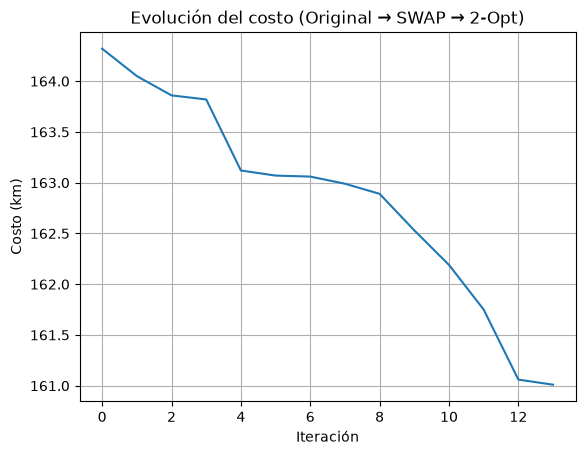

//////////////////
MENU DE COSTOS Y GRAFICOS
1. Resumen de costos de los metodos implementados
2. Graficas de cada metodo
3. Grafica de costos de mejora
4. Salir
//////////////////
//////////////////
RESUMEN DE COSTOS
costo original   : 164.32
costo swap       : 161.74999999999997
costo twoOptimal : 161.01000000000002
//////////////////
//////////////////
MENU DE COSTOS Y GRAFICOS
1. Resumen de costos de los metodos implementados
2. Graficas de cada metodo
3. Grafica de costos de mejora
4. Salir
//////////////////


In [ ]:
########## MENU INTERACTIVO  ##########

def pedir_entero(mensaje, minv, maxv):
    """Lee un entero validado; ignora entradas vacías o no numéricas."""
    while True:
        valor = input(mensaje).strip()
        if valor == "":
            print("Entrada vacía. Intente de nuevo.")
            continue
        try:
            n = int(valor)
        except ValueError:
            print("Debe ingresar un número entero.")
            continue
        if n < minv or n > maxv:
            print(f"Número fuera de rango ({minv}-{maxv}).")
            continue
        return n


costo_original   = 0
costo_swap       = 0
costo_twoOptimal = 0
band  = True

while band:
    print("//////////////////")
    print("MENU DE COSTOS Y GRAFICOS")
    print("1. Resumen de costos de los metodos implementados")
    print("2. Graficas de cada metodo")
    print("3. Grafica de costos de mejora")
    print("4. Salir")
    print("//////////////////")

    num = pedir_entero("Por introduzca el numero: ", 1, 4)

    if num == 1:
        print("//////////////////")
        print("RESUMEN DE COSTOS")

        costo_original   = sum(r[0] for r in rutas_optmizadas)
        costo_swap       = sum(r[0] for r in rutas_optmizadas_2)
        costo_twoOptimal = sum(r[0] for r in rutas_optmizadas_3)
        print("costo original   :", costo_original)
        print("costo swap       :", costo_swap)
        print("costo twoOptimal :", costo_twoOptimal)
        print("//////////////////")

    elif num == 2:
        band2 = True
        while band2:
            print("//////////////////")
            print("RESUMEN GRAFICO DE LOS METODOS IMPLEMENTADOS")
            print("1. Grafica de ruta original")
            print("2. Grafica de ruta Swap")
            print("3. Grafica de ruta Two Optimal")
            print("4. Grafica del metodo 1 con el 2")
            print("5. Grafica del metodo 2 con el 3")
            print("6. Grafica del metodo 1 con el 3")   
            print("7. Salir")
            print("//////////////////")

            num2 = pedir_entero("Por introduzca el numero: ", 1, 7)
            print("//////////////////")

            if num2 == 1:
                menu_graficas(rutas_optmizadas)
            elif num2 == 2:
                menu_graficas(rutas_optmizadas_2)
            elif num2 == 3:
                menu_graficas(rutas_optmizadas_3)
            elif num2 == 4:
                menu_graficas_combinadas(rutas_optmizadas,   rutas_optmizadas_2)
            elif num2 == 5:
                menu_graficas_combinadas(rutas_optmizadas_2, rutas_optmizadas_3)
            elif num2 == 6:
                menu_graficas_combinadas(rutas_optmizadas,   rutas_optmizadas_3)  
            elif num2 == 7:
                band2 = False

    elif num == 3:
        plt.figure()
        plt.plot(costList)
        plt.title("Evolución del costo (Original → SWAP → 2-Opt)")
        plt.xlabel("Iteración")
        plt.ylabel("Costo (km)")
        plt.grid(True)
        plt.show()

    elif num == 4:
        band = False

In [ ]:
plt.show()

In [ ]:
import os
from datetime import datetime
import pandas as pd


def exportar_rutas_hospital(lista_rutas, writer, prefijo):
 
    for hosp in ['H1', 'H2', 'H3']:
        filas = []
        for i, (costo, df_ruta) in enumerate(lista_rutas):
            if df_ruta.iat[0, 0] != hosp:
                continue
            cierra = df_ruta.iat[-1, 0] == hosp
            filas.append({'cliente': f"=== RUTA {i+1} | costo(km)={float(costo):.4f} "
                                     f"| cierra_en={df_ruta.iat[-1,0]} "
                                     f"| {'OK' if cierra else 'NO CIERRA'} ==="})
            for cli in df_ruta['cliente'].tolist():
                filas.append({'cliente': cli})
            filas.append({'cliente': ''})
        df = pd.DataFrame(filas)
        df.to_excel(writer, sheet_name=f"{prefijo}_{hosp}", index=False)


base = "DATOSPROYECTO"
path = f"{base}.xlsx"
try:
    if os.path.exists(path):
        os.remove(path)
except PermissionError:
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    path = f"{base}_{ts}.xlsx"

with pd.ExcelWriter(path, engine='openpyxl', mode='w') as writer:
    tabdistan.to_excel(writer, sheet_name='rutas iniciales')
    rta_subrutas.to_excel(writer, sheet_name='Sol inicial')
    rta_rutas_optmizadas.to_excel(writer, sheet_name='asig inicial')
    rta_rutas_optmizadas_costos.to_excel(writer, sheet_name='costos asig ini')
    rta_rutas_optmizadas_2.to_excel(writer, sheet_name='ruta luego de SWAP')
    rta_rutas_optmizadas_costos_2.to_excel(writer, sheet_name='costo ruta SWAP')
    rta_rutas_optmizadas_3.to_excel(writer, sheet_name='ruta optmizada con 2OPT')
    rta_rutas_optmizadas_costos_3.to_excel(writer, sheet_name='costo ruta 2OPT')

    exportar_rutas_hospital(rutas_optmizadas,   writer, 'orig')
    exportar_rutas_hospital(rutas_optmizadas_2, writer, 'swap')
    exportar_rutas_hospital(rutas_optmizadas_3, writer, '2opt')

print(f"✅ Guardado en: {os.path.abspath(path)}")

✅ Guardado en: c:\Users\joseg\Documents\4 SEMESTRE\DECISIONES\4_PROYECTO_HEUR\1_SITUACION INICIAL\DATOSPROYECTO_20261018_204138.xlsx
